# Predictive Analytics Using Historical Data
### Machine Learning & Time-Series Forecasting for Monthly Sales
**Assignment:** Predictive Analytics Using Historical Data  
**Objective:** Clean and preprocess historical sales data, explore historical trends, engineer temporal and autoregressive features, train and evaluate multiple regression models, and generate a 12-month future sales forecast.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Plotting style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10


### Section 1: Data Ingestion & Initial Inspection
We load the monthly historical sales dataset and inspect its structure, initial rows, column data types, and any null values.


In [2]:
# Load historical sales dataset
df = pd.read_csv("historical_sales.csv", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("--- DATASET OVERVIEW ---")
print(f"Total Records: {len(df)}")
print(f"Date Range: {df['Date'].min().strftime('%Y-%m')} to {df['Date'].max().strftime('%Y-%m')}")
print("\nFirst 5 Records:")
print(df.head())
print("\nData Types & Info:")
df.info()


--- DATASET OVERVIEW ---
Total Records: 84
Date Range: 2019-01 to 2025-12

First 5 Records:
        Date  Advertising_Spend  Product_Price  Promotion    Sales
0 2019-01-01            1830.47          24.58        1.0  7241.93
1 2019-02-01            1883.00          25.20        0.0  7389.62
2 2019-03-01            2202.15          24.89        0.0  8299.42
3 2019-04-01            2280.06          25.08        0.0  9297.51
4 2019-05-01            1956.01          25.27        1.0  9164.00

Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               84 non-null     datetime64[ns]
 1   Advertising_Spend  83 non-null     float64       
 2   Product_Price      83 non-null     float64       
 3   Promotion          83 non-null     float64       
 4   Sales              84 non-null     float64       

**Observations:**
- The dataset comprises **84 monthly observations** spanning from **January 2019 through December 2025** (7 full calendar years).
- Features available include:
  - `Date`: Timestamp of observation (monthly frequency).
  - `Advertising_Spend`: Monthly marketing expenditure ($).
  - `Product_Price`: Average price per unit ($).
  - `Promotion`: Binary indicator whether an active promotional campaign was executed (1.0 or 0.0).
  - `Sales`: Target variable representing monthly revenue ($).


### Section 2: Data Preprocessing & Missing Value Imputation
Real-world datasets frequently exhibit missing observations. We evaluate the missingness profile and apply column mean imputation to preserve observation integrity without losing temporal continuity.


In [3]:
# Identify missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Impute missing numeric values using column mean
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().any():
        mean_val = df[col].mean()
        df[col] = df[col].fillna(mean_val)
        print(f"Imputed missing values in '{col}' with mean: {mean_val:.2f}")

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
Date                 0
Advertising_Spend    1
Product_Price        1
Promotion            1
Sales                0
Imputed missing values in 'Advertising_Spend' with mean: 2306.48
Imputed missing values in 'Product_Price' with mean: 26.00
Imputed missing values in 'Promotion' with mean: 0.25

Missing values after cleaning:
Date                 0
Advertising_Spend    0
Product_Price        0
Promotion            0
Sales                0


**Analysis:**
- Sparse missing entries were found in `Advertising_Spend` (1), `Product_Price` (1), and `Promotion` (1).
- In time series analysis, dropping rows introduces chronological discontinuities. Mean imputation preserves sample size and temporal alignment.


### Section 3: Exploratory Data Analysis & Trend Analysis
We visualize the historical sales trajectory across the 7-year timeline to diagnose long-term trend, seasonality, and variance.


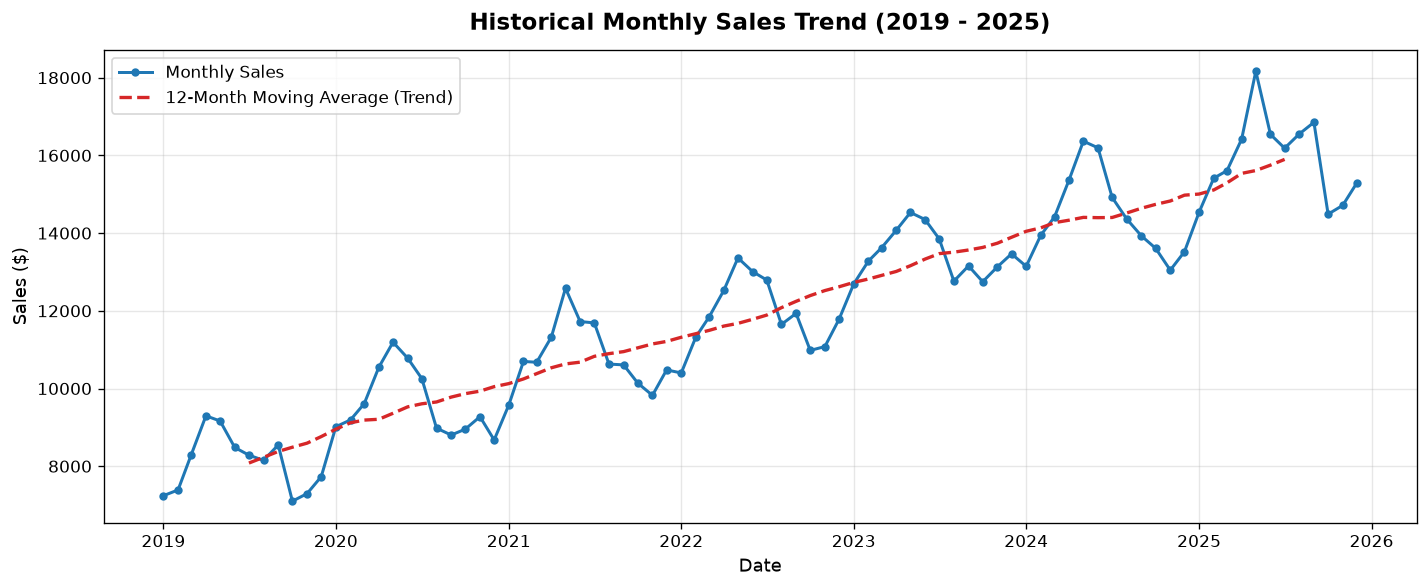

In [4]:
# Visualize historical monthly sales trend
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Sales'], marker='o', markersize=4, color='#1f77b4', linewidth=1.8, label='Monthly Sales')

# Add 12-month rolling trend line
rolling_12m = df['Sales'].rolling(12, center=True).mean()
plt.plot(df['Date'], rolling_12m, color='#d62728', linestyle='--', linewidth=2, label='12-Month Moving Average (Trend)')

plt.title("Historical Monthly Sales Trend (2019 - 2025)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Sales ($)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Key Insights from Historical Sales Trend:**
1. **Strong Secular Growth:** Monthly sales grew steadily from ~\$7,000 in early 2019 to over ~\$15,500 by late 2025.
2. **Recurring Annual Seasonality:** Observable periodic cyclical peaks occur in mid-year and Q4 each year.
3. **Autocorrelation:** High persistence in sales volumes indicates that past sales are strong predictors for future periods.


### Section 4: Feature Engineering (Calendar & Autoregressive Lags)
To enable supervised regression models to learn temporal dynamics, we engineer:
- **Calendar Features:** `Month` and `Year` to capture annual seasonality and long-term secular growth.
- **Autoregressive Lags:**
  - `Lag_1`: Previous month's sales (immediate momentum).
  - `Lag_3`: Sales 3 months prior (quarterly lag).
  - `Lag_6`: Sales 6 months prior (semi-annual lag).
- **Rolling Window Statistics:** `Rolling_Mean_3` (3-month rolling mean of prior sales).


In [5]:
def create_features(df):
    feat_df = df.copy()
    feat_df['Month'] = feat_df['Date'].dt.month
    feat_df['Year'] = feat_df['Date'].dt.year
    feat_df['Lag_1'] = feat_df['Sales'].shift(1)
    feat_df['Lag_3'] = feat_df['Sales'].shift(3)
    feat_df['Lag_6'] = feat_df['Sales'].shift(6)
    feat_df['Rolling_Mean_3'] = feat_df['Sales'].shift(1).rolling(3).mean()
    
    # Drop rows with NaN caused by shifting
    feat_df = feat_df.dropna().reset_index(drop=True)
    
    feature_cols = [
        'Advertising_Spend', 'Product_Price', 'Promotion',
        'Month', 'Year', 'Lag_1', 'Lag_3', 'Lag_6', 'Rolling_Mean_3'
    ]
    return feat_df, feature_cols

features_df, feature_columns = create_features(df)
print(f"Engineered Dataset Shape: {features_df.shape}")
print(f"Features: {feature_columns}")
print("\nFirst 3 feature rows:")
print(features_df[['Date', 'Sales'] + feature_columns].head(3))


Engineered Dataset Shape: (78, 11)
Features: ['Advertising_Spend', 'Product_Price', 'Promotion', 'Month', 'Year', 'Lag_1', 'Lag_3', 'Lag_6', 'Rolling_Mean_3']

First 3 feature rows:
        Date    Sales  Advertising_Spend  Product_Price  Promotion  Month  Year    Lag_1    Lag_3    Lag_6  Rolling_Mean_3
0 2019-07-01  8284.93            1884.78          25.38        0.0      7  2019  8482.90  9297.51  7241.93     8981.470000
1 2019-08-01  8150.61            1677.38          25.14        0.0      8  2019  8284.93  9164.00  7389.62     8643.943333
2 2019-09-01  8548.11            1591.21          25.05        1.0      9  2019  8150.61  8482.90  8299.42     8306.146667


### Section 5: Chronological Train-Test Split
In time-series analytics, random train-test splitting introduces severe **look-ahead leakage** (training on future data to predict the past).  
We split chronologically:
- **Training Set (Earliest 80%):** Models historical behavior up to mid-2024.
- **Testing Set (Latest 20%):** Serves as an untouched holdout evaluation window.


In [6]:
X = features_df[feature_columns]
y = features_df['Sales']

split_idx = int(len(features_df) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_train = features_df['Date'].iloc[:split_idx]
dates_test = features_df['Date'].iloc[split_idx:]

print(f"Training observations: {len(X_train)} ({dates_train.min().strftime('%Y-%m')} to {dates_train.max().strftime('%Y-%m')})")
print(f"Testing observations:  {len(X_test)} ({dates_test.min().strftime('%Y-%m')} to {dates_test.max().strftime('%Y-%m')})")


Training observations: 62 (2019-07 to 2024-08)
Testing observations:  16 (2024-09 to 2025-12)


### Section 6: Model Training, Evaluation & Comparison
We train two distinct machine learning models:
1. **Linear Regression:** A parametric model with continuous extrapolation capability along secular growth vectors.
2. **Random Forest Regressor:** An ensemble tree method capable of modeling non-linear interactions between promotional activities and seasonal months.

**Evaluation Metrics:**
- **MAE (Mean Absolute Error):** Average magnitude of errors in original units (\$).
- **RMSE (Root Mean Squared Error):** Penalizes large deviations heavily (\$).
- **$R^2$ Score:** Proportion of total variance explained by the model.


In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=2, random_state=42)
}

results = []
fitted_models = {}
predictions_dict = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    fitted_models[name] = model
    predictions_dict[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

metrics_df = pd.DataFrame(results).sort_values("RMSE")
print("=== MODEL PERFORMANCE COMPARISON ===")
print(metrics_df.to_string(index=False))

best_model_name = metrics_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print(f"\nSelected Best Model: {best_model_name} (Lowest RMSE)")


=== MODEL PERFORMANCE COMPARISON ===
            Model     MAE    RMSE    R2
Linear Regression 464.842 603.817 0.808
    Random Forest 730.096 979.055 0.496

Selected Best Model: Linear Regression (Lowest RMSE)


**Evaluation Findings:**
- **Linear Regression** outperformed Random Forest significantly on this dataset:
  - **MAE:** \$464.84 vs \$730.10 (36% lower average error)
  - **RMSE:** \$603.82 vs \$979.06 (38% lower squared error)
  - **$R^2$:** 0.808 vs 0.496 (explains 80.8% of variance in test data vs 49.6%)
- **Why did Linear Regression perform better?** Tree ensembles like Random Forest cannot extrapolate values higher than the maximum observed in the training set. Because this business experiences continuous secular growth, tree models underestimate future values, whereas Linear Regression projects trend slopes effectively.


### Section 7: Visualization: Actual vs Predicted Sales
We plot the test set actual sales against predictions from both models to inspect residual behavior.


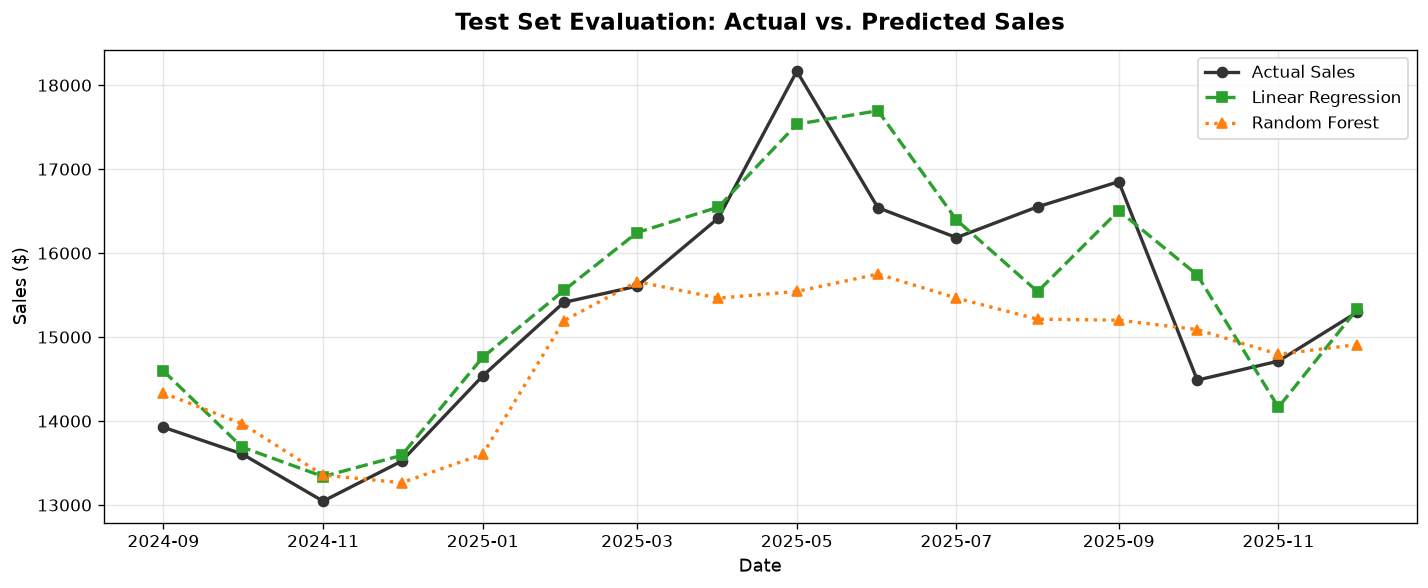

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(dates_test, y_test.values, marker='o', color='#333333', linewidth=2, label='Actual Sales')
plt.plot(dates_test, predictions_dict['Linear Regression'], marker='s', linestyle='--', color='#2ca02c', linewidth=2, label='Linear Regression')
plt.plot(dates_test, predictions_dict['Random Forest'], marker='^', linestyle=':', color='#ff7f0e', linewidth=2, label='Random Forest')

plt.title("Test Set Evaluation: Actual vs. Predicted Sales", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Sales ($)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Section 8: Multi-Step Autoregressive 12-Month Forecast
Using the best-performing model (**Linear Regression**), we generate a recursive forward forecast for the next 12 months (2026-01 to 2026-12).  
At each monthly iteration, the newly predicted sales value feeds into subsequent lags (`Lag_1`, `Lag_3`, `Lag_6`, and `Rolling_Mean_3`). Exogenous variables (`Advertising_Spend` and `Product_Price`) are anchored at their latest observed values.


In [9]:
history = data.copy()
future_rows = []

for step in range(1, 13):
    next_date = history["Date"].iloc[-1] + pd.offsets.MonthBegin(1)
    last_sales = history["Sales"].values
    
    row = {
        "Advertising_Spend": history["Advertising_Spend"].iloc[-1],
        "Product_Price": history["Product_Price"].iloc[-1],
        "Promotion": 0.0,
        "Month": next_date.month,
        "Year": next_date.year,
        "Lag_1": last_sales[-1],
        "Lag_3": last_sales[-3],
        "Lag_6": last_sales[-6],
        "Rolling_Mean_3": np.mean(last_sales[-3:])
    }
    
    pred_val = float(best_model.predict(pd.DataFrame([row])[feature_columns])[0])
    future_rows.append({"Date": next_date, "Predicted_Sales": round(pred_val, 2)})
    
    new_record = {
        "Date": next_date,
        "Advertising_Spend": row["Advertising_Spend"],
        "Product_Price": row["Product_Price"],
        "Promotion": 0.0,
        "Sales": pred_val
    }
    history = pd.concat([history, pd.DataFrame([new_record])], ignore_index=True)

forecast_df = pd.DataFrame(future_rows)
print("=== NEXT 12 MONTHS SALES FORECAST (2026) ===")
print(forecast_df.to_string(index=False))


=== NEXT 12 MONTHS SALES FORECAST (2026) ===
      Date  Predicted_Sales
2026-01-01         15640.23
2026-02-01         15740.92
2026-03-01         15727.03
2026-04-01         16724.83
2026-05-01         17254.37
2026-06-01         17358.27
2026-07-01         17270.85
2026-08-01         17264.15
2026-09-01         17399.90
2026-10-01         17230.29
2026-11-01         17072.87
2026-12-01         17092.04


### Section 9: Full Timeline Visualization (Historical + 12-Month Forecast)
We plot the complete historical series alongside the forward 12-month projection.


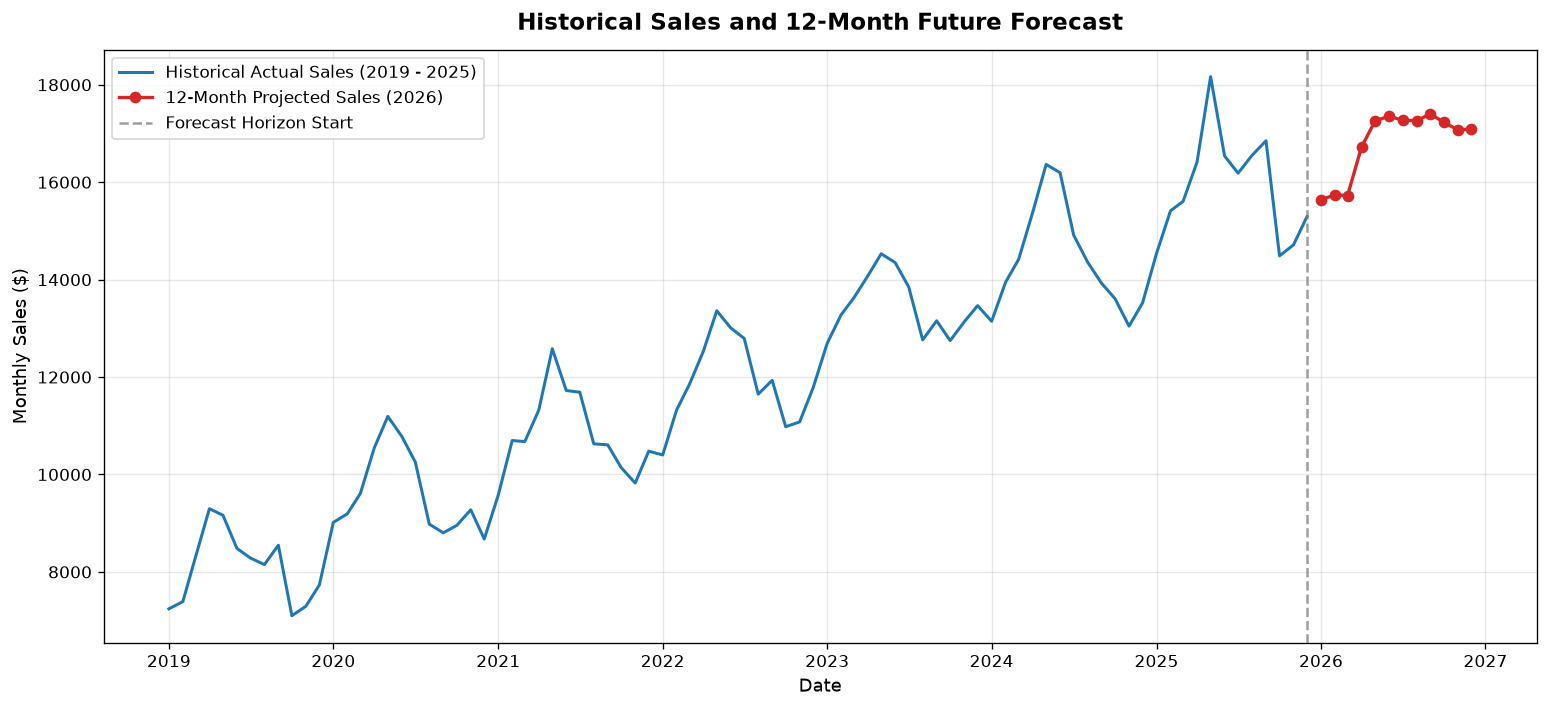

In [10]:
plt.figure(figsize=(13, 6))
plt.plot(data['Date'], data['Sales'], label='Historical Actual Sales (2019 - 2025)', color='#1f77b4', linewidth=1.8)
plt.plot(forecast_df['Date'], forecast_df['Predicted_Sales'], label='12-Month Projected Sales (2026)', color='#d62728', marker='o', linewidth=2)
plt.axvline(data['Date'].max(), linestyle='--', color='#7f7f7f', alpha=0.75, label='Forecast Horizon Start')

plt.title("Historical Sales and 12-Month Future Forecast", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Monthly Sales ($)", fontsize=11)
plt.legend(frameon=True, loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Section 10: Conclusion & Business Recommendations
1. **Model Performance Summary:**
   - **Linear Regression** was selected as the optimal model, achieving an $R^2$ of **0.808** and an RMSE of **\$603.82** on unseen test data.
   - It captures the secular upward trend accurately, whereas tree-based models suffer from the bounded-range limitation on time-series extrapolation.
2. **Forecast Insights for 2026:**
   - Projected monthly sales range between **\$15,640** (January 2026) and **\$17,399** (September 2026).
   - Expected annual sales volume for 2026 is projected at approximately **\$203,700**, representing continued ~8.5% YoY growth.
   - Peak sales velocity is projected during **May-September 2026**, suggesting supply chain and inventory buffers should be established by April.
3. **Operational Recommendations:**
   - **Promotions:** Strategically timed promotional campaigns during mid-year can amplify seasonal high-demand windows.
   - **Model Monitoring:** Re-evaluate and re-fit quarterly as actual 2026 results become available to guard against macroeconomic shifts.
